### **การเขียนโปรแกรมด้วย Libraly NumPy สำหรับการจัดการข้อมูลเสียง**

---

**N1 (โค้ด) ตัดช่วงสัญญาณด้วย slicing**
  - **สร้างอะไร:** `sr = 22050`, สัญญาณ sine 440 Hz แอมพลิจูด 1 ยาว 1 วินาที (ใช้ `create_sin` ของเมื่อวานได้) แล้วเขียนฟังก์ชัน `get_segment(x, sr, start_s, end_s)` ที่คืนเฉพาะช่วงเวลาที่ขอ (ใบ้: แปลงวินาทีเป็น index แล้วต้องเป็น `int`)
  - **ทดสอบ:** ขอช่วง 0.50–0.52 s แล้ว print `.shape` และ `.dtype` ของผลลัพธ์ จากนั้นพล็อตช่วงนี้โดยแกน x เป็นมิลลิวินาทีที่ **เริ่มที่ 500 ms** ไม่ใช่ 0
  - **ทดลองเพิ่ม:** แก้ค่าในช่วงที่ตัดมา (เช่น `seg[:] = 0`) แล้วเช็คว่าสัญญาณต้นฉบับเปลี่ยนไหม
  - **ตอบ 2 ข้อ:** (1) ช่วง 20 ms ได้กี่ sample และคำนวณด้วยมือตรงกับ `.shape` ไหม (2) ต้นฉบับเปลี่ยนหรือไม่ เพราะอะไร (ค้นคำว่า NumPy view vs copy) และถ้าไม่อยากให้เปลี่ยนต้องใช้อะไร
  - **เสร็จเมื่อ:** shape ตรงกับที่คำนวณ, กราฟแกน x เริ่มที่ 500 ms และตอบครบ 2 ข้อ

---

**ตอบ**: 
1. จากการคำนวณ $n_{T_{sr}} = T_{sr} \times S_r$ \
เมื่อ $n_{T_{sr}}$ คือ จำนวน Sampling ในช่วงเวลาที่ต้องการ, $T_{sr}$ คือ ช่วงเวลาที่ต้องการ และ $S_r$ คือ อัตราการ Sampling\
จะได้ว่า $T_{sr} = 20 \times 10^{-3} s, S_r = 22050$ \
ดังนั้น $n_{T_{sr}} = 20 \times 10^{-3} \times 22050 = 441$ และตรงกับ `.shape` ซึ่งเท่ากับ 441

2. NumPy as view copy จะมีฟังก์ชัน 2 แบบคือ arr.view() และ arr.copy() ความแตกต่างระหว่าง view และ copy คือ view จะชี้ไปยัง array ต้นฉบับมาและเมื่อมีการแก้ไขจะกระทบกับ array หลัก ในขณะที่ copy เมื่อมีการแก้ไขจะไม่กระทบกับ array หลัก ถ้าต้องการไม่ให้เปลี่ยนให้ใช้ `array.copy()` พบว่าสัญญาณต้นฉบับมีการเปลี่ยนแปลง เพราะว่า slicing ของ NumPy `x[a:b]` จะ Return ออกมาเป็น view ถ้าต้องการให้สัญญาณต้นไม่มีการเปลี่ยนแปลงให้ใช้ `x[a:b].copy()`

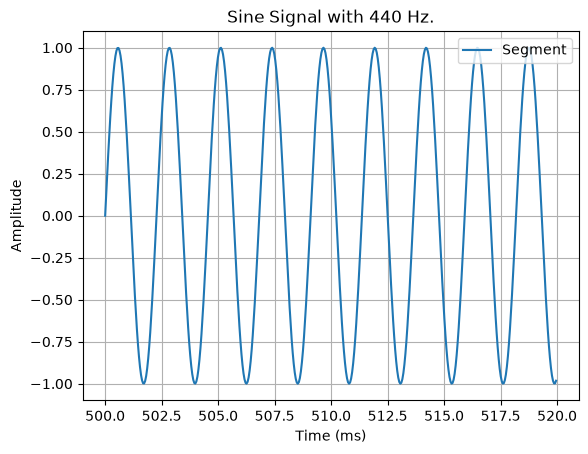

This is .shape of signal : (441,)
This is .dtype of signal : float64


In [1]:
# เขียนโปรแกรมสำหรับการสร้างสัญญาณ Sine ที่มีความถี่เท่ากับ 440 Hz, แอมพลิจูดเท่ากับ 1, ระยะเวลา 1 วินาที
import numpy as np
import matplotlib.pyplot as plt

frequency = 440 # Frequency ความถี่
amplitude = 1   # Amplitude แอมพลิจูด
sr = 22050      # Sampling Rate 
start_s = 0.5
end_s = 0.52

t = np.arange(0, 1, 1/sr)

# ฟังก์ชันสำหรับสร้างสัญญาณ Sine
def create_sin(A, f, t, phase=0):
    signal = A * np.sin((2 * np.pi * f * t) + phase)
    return signal

# ฟังก์ชันสำหรับการเลือกช่วงมาพล็อตกราฟ
def get_segment(signal, sr, start_s, end_s):
    n_start = int(sr * start_s) # สร้างตัวแปร index ของ Sample ที่เป็นตัวแรกของสัญญาณ
    n_end = int(sr * end_s)     # สร้างตัวแปร index ของ Sample ที่เป็นตัวสุดท้ายของสัญญาณ

    # ทำการ Return ค่าหลายค่าออกมาเป็น Tuples
    return signal[n_start:n_end], n_start, n_end

sine_signal = create_sin(amplitude, frequency, t)   # สร้างสัญญาณ Sine
# ทำการเลือกช่วงสัญญาณที่ต้องการผ่านฟังก์ชัน get_segment จะได้เป็น Index เริ่มต้นและสุดท้ายของสัญญาณ
segment_signal, n_start, n_end = get_segment(sine_signal, sr, start_s, end_s)


fig, ax = plt.subplots()
ax.grid()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Sine Signal with 440 Hz.")
ax.plot(t[n_start:n_end]*1000, segment_signal, label="Segment")
ax.legend(loc="upper right")
plt.show()

# ทำการแสดงผลลัพธ์ของ Signal
print(f'This is .shape of signal : {segment_signal.shape}')
print(f'This is .dtype of signal : {segment_signal.dtype}')

In [2]:
# ทำการทดลองเกี่ยวกับ NumPy as view copy

# .copy()
print(f"This is original signal : {sine_signal[11025:11030]}")
segment_signal = sine_signal[11025:11030].copy()
segment_signal[:] = 0 
print(f"This is original signal after .copy() : {sine_signal[11025:11030]}")

This is original signal : [3.13806691e-14 1.25050524e-01 2.48137848e-01 3.67329594e-01
 4.80754541e-01]
This is original signal after .copy() : [3.13806691e-14 1.25050524e-01 2.48137848e-01 3.67329594e-01
 4.80754541e-01]


In [3]:
print(f"This is original signal : {sine_signal[11025:11030]}")
segment_signal = sine_signal[11025:11030]    # ชี้ไปยัง Array sine_signal 
segment_signal[:] = 0   # กำหนดค่าทุกค่าใน Array เท่ากับ 0
print(f"This is original signal after segment_signal[:] = 0 : {sine_signal[11025:11030]}")

This is original signal : [3.13806691e-14 1.25050524e-01 2.48137848e-01 3.67329594e-01
 4.80754541e-01]
This is original signal after segment_signal[:] = 0 : [0. 0. 0. 0. 0.]


**N2 (โค้ด + ทฤษฎี) `==` กับ `np.allclose`**
  - **สร้างอะไร:** `x = 2*np.pi*440*t` จาก N1 แล้วสร้าง `a = np.sin(x + np.pi/2)` กับ `b = np.cos(x)`
  - **เทียบคู่ที่ 1:** `a` กับ `b` → print ผลของ `np.all(a == b)`, `np.allclose(a, b)` และ `np.max(np.abs(a - b))`
  - **เทียบคู่ที่ 2:** sine 440 Hz ช่วง sample `[0:100]` กับช่วงที่เลื่อนไป **1 วินาทีพอดี** `[22050:22150]` (ต้องสร้างสัญญาณยาวกว่า 1 วินาทีก่อน)
  - **เทียบคู่ที่ 3:** ช่วง `[0:100]` กับช่วงที่เลื่อนไป **50 sample** `[50:150]` (ประมาณ 1 คาบ)
  - **ตอบ 3 ข้อ:** (1) ทำไมคู่ที่ 1 ใช้ `==` แล้วได้ False ทั้งที่ทางคณิตศาสตร์เท่ากัน (2) คาบของ 440 Hz ยาวกี่ sample (ทศนิยม 2 ตำแหน่ง) (3) ใช้ข้อ (2) อธิบายว่าทำไมคู่ที่ 2 เป็น True แต่คู่ที่ 3 เป็น False
  - **เสร็จเมื่อ:** print ผลครบทั้ง 3 คู่ (คู่ละ `allclose` + max abs diff) และตอบครบ 3 ข้อ

  ___

  **ตอบ** : 
  1. เพราะคอมพิวเตอร์เก็บข้อมูลแบบเลขฐาน 2 และคอมพิวเตอร์ไม่สามารถเก็บตัวเลขแบบทศนิยมได้ละเอียดเหมือนทางคณิตศาสตร์และค่า $\frac{\pi}{2}$ ในทางคอมพิวเตอร์ก็ไม่สามารถเก็บได้ตรงเป๊ะ การใช้คำสั่ง `==` คือการเปรียบเทียบว่าค่าของ Operand 2 ตัวเท่ากันหรือไม่ ถ้าเท่ากันก็ Return เป็น True ถ้าไม่ก็ Return เป็น False และคำสั่ง np.all() เป็นการเปรียบเทียบกันทุกจุด ถ้ามีจุดใดจุดหนึ่ง Return เป็น False np.all() ก็จะ Return เป็น False ทันที ซึ่งในคำสั่งการตรวจสอบ Diff มี Diff เล็กน้อย ซึ่งโปรแกรมก็จะถือว่าไม่เท่ากันเลยมีการ Return เป็น False ออกมา
 

  2. คาบของสัญญาณ 440 Hz ยาวกี่ Sample สามารถคำนวณหาได้จาก \
  คาบของสัญญานสามารถคำนวณได้จาก $\frac{1}{440} \approx 2.273 \times 10^{-3} s$ \
  $S_r = 22050$
  1 คาบสัญญาณของสัญญาณ Sine 440 Hz มีจำนวน Sample เท่ากับ 50.11 samples

  3. คลื่นจะวนกลับมาซ้ำที่เดิมก็ต่อเมื่อเป็นจำนวนเต็มของคาบเท่านั้น แต่คาบของ 440 Hz ยาว 50.11 sample ซึ่งไม่ใช่จำนวนเต็ม จึงเลื่อนด้วยจำนวน Sample ที่เป็นจำนวนเต็มให้ครบ 1 รอบพอดีไม่ได้ ต้องเลื่อนไปไกลถึง 22050 Sample โดยในคู่ที่ 2 มีการเลื่อน Sample ไป 22050 Samples พอดี (= 440 รอบพอดี) และค่า Diff มีค่าเท่ากับ $4.7 \times 10^{-13}$ ซึ่งเข้าเงื่อนไขให้ np.allclose(a,b) return เป็น True ในขณะที่คู่ที่ 3 มีการเลื่อน Sample ไป 50 Samples (= 0.9977 รอบไม่ครบ 1 รอบ) และค่า Diff มีค่าเท่ากับ 0.0142 ซึ่งเข้าเงื่อนไขให้ np.allclose(a,b) return เป็น False

In [4]:
# คำนวณหาคาบของสัญญาณ Sine 440 Hz
period = 1/440
print(f'Period : {period:.3e}')

sample_1_period = sr * period
print(f'1 Period of Signal has {round(sample_1_period,2)} samples')

Period : 2.273e-03
1 Period of Signal has 50.11 samples


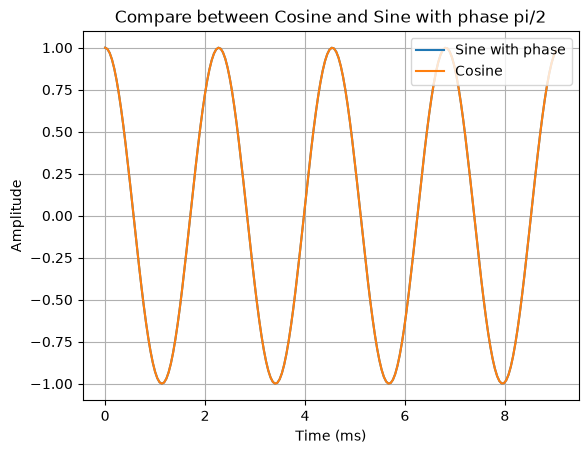

Compare between Cosine and Sine with phase pi/2
-----------------------------------------------
Results of np.all(a==b) : False
Results of np.allclose(a, b) : True
Rsults of np.max(np.abs(a - b)) : 1.6513992864147786e-13


In [5]:
# สร้างสัญญาณ Sine และ Cosine 
x = 2  *np.pi * frequency * t

a = np.sin(x + (np.pi/2))   # สร้างสัญญาณ Sine ที่มีมุมเฟสเท่ากับ pi/2 
b = np.cos(x)               # สร้างสัญญาณ Cosine

# -- Plot Graph --
fig, ax = plt.subplots()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Compare between Cosine and Sine with phase pi/2")
ax.grid()

# ต้องการให้แสดงคลื่นทั้งหมด 4 ลูก 1 ลูกเท่ากับ 1/440 อัตรา Sampling เท่ากับ 22050 ดังนั้น 4 * (1/440) * 22050 = 200
ax.plot(t[0:200]*1000, a[0:200], label="Sine with phase") 
ax.plot(t[0:200]*1000, b[0:200], label="Cosine")
ax.legend(loc="upper right")

plt.show()

# เปรียบเทียบคู่ที่ 1 a และ b
print("Compare between Cosine and Sine with phase pi/2")
print("-----------------------------------------------")
print(f'Results of np.all(a==b) : {np.all(a == b)}')    # เป็นการเช็คแต่ละค่าใน index เดียวกันเทียบเรียงตัว ถ้ามีตัวใดตัวหนึ่ง False ก็จะ False เลย
print(f'Results of np.allclose(a, b) : {np.allclose(a,b)}') # เป็นการเช็คแต่ละค่าใน index เดียวกันเทียบเรียงตัวเหมือนกัน แต่ว่าขอแค่ใกล้เคียงมากพอประมาณ atol + rtol × |b| 
print(f'Rsults of np.max(np.abs(a - b)) : {np.max(np.abs(a - b))}') # เปรียบเทียบจุดแต่ละจุดของกราฟนำมาลบกันและผ่านค่าสัมบูรณ์แล้วเลือกจุดที่แตกต่างกันมากที่สุด


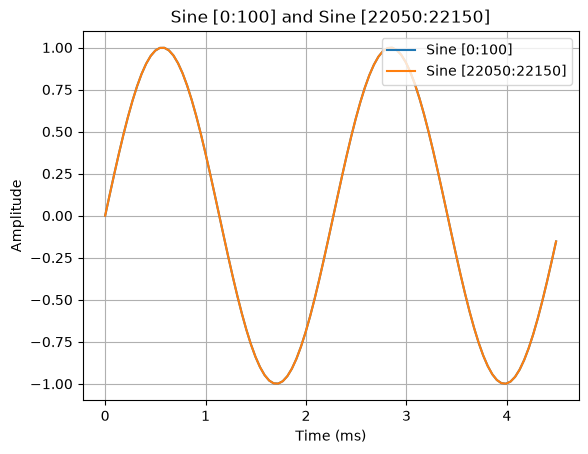

Sine [0:100] and Sine [22050:22150]
-----------------------------------
Results of np.all(a==b) : False
Results of np.allclose(a, b) : True
Rsults of np.max(np.abs(a - b)) : 4.711231404996852e-13


In [6]:
# เปรียบเทียบคู่ที่ 2

# สร้างช่วงระยะเวลาสำหรับการแสดงสัญญาณ 2 วินาที
t_2 = np.arange(0, 2, 1/sr)

x_2 = 2 * np.pi * frequency * t_2   

a_2 = np.sin(x_2)   # สร้างสัญญาณ Sine ระยะเวลา 2 วินาที
Sine_1st_interval = a_2[0:100]
Sine_2nd_interval = a_2[22050:22150]

# -- Plot Graph --
fig, ax = plt.subplots()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Sine [0:100] and Sine [22050:22150]")
ax.grid()

ax.plot(t_2[0:100]*1000, Sine_1st_interval, label="Sine [0:100]")
ax.plot(t_2[0:100]*1000, Sine_2nd_interval, label="Sine [22050:22150]")
ax.legend(loc="upper right")
plt.show()

# -- เปรียบเทียบระหว่าง Sine [0:100] และ Sine [22050:22150] --
print("Sine [0:100] and Sine [22050:22150]")
print("-----------------------------------")
print(f'Results of np.all(a==b) : {np.all(Sine_1st_interval == Sine_2nd_interval)}')    # เป็นการเช็คแต่ละค่าใน index เดียวกันเทียบเรียงตัว ถ้ามีตัวใดตัวหนึ่ง False ก็จะ False เลย
print(f'Results of np.allclose(a, b) : {np.allclose(Sine_1st_interval,Sine_2nd_interval)}') # เป็นการเช็คแต่ละค่าใน index เดียวกันเทียบเรียงตัวเหมือนกัน แต่ว่าขอแค่ใกล้เคียงมากพอประมาณ atol + rtol × |b|
print(f'Rsults of np.max(np.abs(a - b)) : {np.max(np.abs(Sine_1st_interval - Sine_2nd_interval))}') # เปรียบเทียบจุดแต่ละจุดของกราฟนำมาลบกันและผ่านค่าสัมบูรณ์แล้วเลือกจุดที่แตกต่างกันมากที่สุด


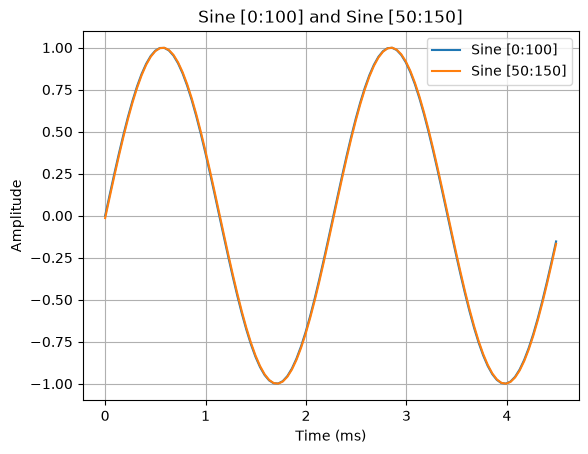

Sine [0:100] and Sine [50:150]
-----------------------------
Results of np.all(a==b) : False
Results of np.allclose(a, b) : False
Rsults of np.max(np.abs(a - b)) : 0.014247103707102927


In [7]:
# เปรียบเทียบคู่ที่ 3 

Sine_1_period = a_2[50:150]

# -- Plot Graph --
fig, ax = plt.subplots()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Sine [0:100] and Sine [50:150]")
ax.grid()

ax.plot(t_2[0:100]*1000, Sine_1st_interval, label="Sine [0:100]")
ax.plot(t_2[0:100]*1000, Sine_1_period, label="Sine [50:150]")
ax.legend(loc="upper right")
plt.show()

# -- เปรียบเทียบระหว่าง Sine [0:100] และ Sine [50:150] --
print("Sine [0:100] and Sine [50:150]")
print("-----------------------------")
print(f'Results of np.all(a==b) : {np.all(Sine_1st_interval == Sine_1_period)}')    # เป็นการเช็คแต่ละค่าใน index เดียวกันเทียบเรียงตัว ถ้ามีตัวใดตัวหนึ่ง False ก็จะ False เลย
print(f'Results of np.allclose(a, b) : {np.allclose(Sine_1st_interval,Sine_1_period)}') # เป็นการเช็คแต่ละค่าใน index เดียวกันเทียบเรียงตัวเหมือนกัน แต่ว่าขอแค่ใกล้เคียงมากพอประมาณ atol + rtol × |b| 
print(f'Rsults of np.max(np.abs(a - b)) : {np.max(np.abs(Sine_1st_interval - Sine_1_period))}') # เปรียบเทียบจุดแต่ละจุดของกราฟนำมาลบกันและผ่านค่าสัมบูรณ์แล้วเลือกจุดที่แตกต่างกันมากที่สุด

**N3 (โค้ด) Normalize และ broadcasting**
  - **สร้างอะไร:** ฟังก์ชัน `normalize_peak(x, target=0.9)` ที่ทำให้ค่า `np.max(np.abs(...))` ของผลลัพธ์เท่ากับ `target` (คิดเองด้วยว่าถ้า `x` เป็นศูนย์ทั้งหมดจะเกิดอะไร แล้วกันไว้)
  - **ทดสอบ:** ใช้กับ `sine_440` และ `sine_with_3_harmonics` ของเมื่อวาน แล้ว print peak ก่อนและหลัง ทั้งสองสัญญาณ
  - **broadcasting:** เอา 3 สัญญาณ (440 ล้วน, 3 harmonics, 3 harmonics แบบมีเฟส) มาซ้อนเป็น array 2 มิติด้วย `np.stack` → print shape แล้วคูณกับ gain `np.array([[1.0], [0.5], [0.25]])` จากนั้นลองคูณกับ `np.array([1.0, 0.5, 0.25])` (ไม่มีวงเล็บชั้นใน)
  - **ตอบ 2 ข้อ:** (1) shape ของ array ที่ซ้อนแล้วคือ (กี่, กี่) และแต่ละมิติหมายถึงอะไร (2) gain แบบ `(3, 1)` คูณได้ แต่แบบ `(3,)` error หรือได้ผลผิด เพราะอะไร (อธิบายด้วยกฎ broadcasting ที่ไล่เทียบมิติจากขวาไปซ้าย)
  - **เสร็จเมื่อ:** peak หลัง normalize เท่ากับ 0.9 ทั้งสองสัญญาณ (เช็คด้วย `np.isclose`) และตอบครบ 2 ข้อ

  ---

  **ตอบ** : 
  x หรือ signal มีค่าเท่ากับ 0 จะทำให้ gain ที่สามารถหาได้จาก $\frac{target}{peak}$ ไม่นิยาม $(\frac{1}{0})$ เลยมีการเขียนโปรแกรมป้องกันเอาไว้ ถ้า signal หรือ peak มีค่าเท่ากับ 0 ให้ return ทันที

  1. Shape ของ Array ที่ซ้อนแล้วคือ (3, 22050) โดยที่เลขตัวแรก 3 คือ จำนวนสัญญาณที่มีการนำมารวมโดยโจทย์ให้มีการรวม 3 สัญญาณเข้าด้วยกันคือ สัญญาณ Sine ความถี่ 440 Hz, สัญญาณ Sine ที่เกิดการรวม Harmonics 3 คลื่นเข้าด้วยกัน และสัญญาณ Sine ที่เกิดการรวม Harmonics 3 คลื่นเข้าด้วยกันแต่ว่าสัญญาณ Sine ความถี่ 880 Hz มีเฟสเท่ากับ $\frac{\pi}{2}$ และเลขตัวที่สองคือจำนวน Sample ของแต่ละสัญญาณในที่นี่คือ 22050

  2. กฎ Broadcasting ของ Numpy คือ การเทียบ Shape ของสองฝั่งจากขวามาซ้าย โดยแต่ละคู่ต้องมีค่าเท่ากันหรือมีตัวใดตัวหนึ่งมีค่าเท่ากับ 1 (ตัวที่เป็น 1 จะถูกยืดให้เท่ากับกับอีกฝั่ง) ถ้ามีคู่ไหนไม่ผ่าน จะเกิด error \
  กรณี gain แบบ (3,1):
  (3, 22050) และ (3,1) ทางขวาสุดของด้านล่างคือ 1 ทำให้มีการถูกยืดไปให้เท่ากับ 22050 และ 3 มีค่าเท่ากับ 3 \
  กรณี gain แบบ (3,):
  (3, 22050) และ (, 3) ทางขวาสุดมีค่าไม่เท่ากันคือ 22050 และ 3 จึงแจ้งเตือน error 

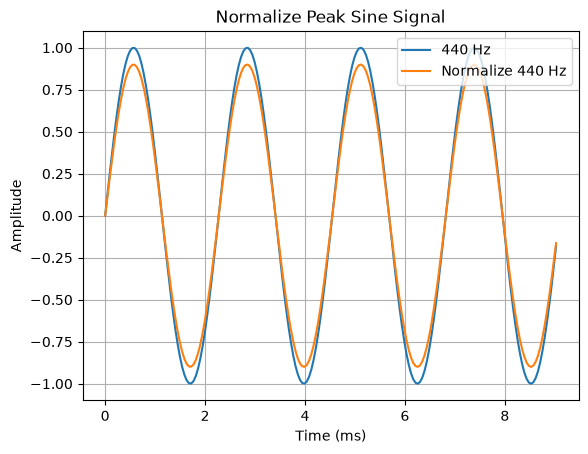

Peak of signal before normalize : 0.999999746257887
Peak of signal after normalize : 0.9
Check normalization : True


In [8]:
# สร้างฟังก์ชันสำหรับการทำให้แอมพลิจูดของทุกสัญญาณเท่ากัน
def normalize_peak(signal, target=0.9):
    # หา peak ของสัญญาณ
    peak = np.max(np.abs(signal))

    # เช็คว่า signal เป็น 0 หรือไม่ ถ้าเท่ากับ 0 ให้ return signal 
    if(peak==0):
        return signal
    
    gain = target / peak    # target = gain * peak (หรือก็คือ signal)

    return signal * gain

# สร้างสัญญาณ Sine ความถี่ต่าง ๆ 
t = np.arange(0, 1, 1/sr)
sine_440 = create_sin(1, frequency, t)      # สร้างสัญญาณ Sine ความถี่ 440 Hz
sine_880 = create_sin(1/2, frequency*2, t)    # สร้างสัญญาณ Sine ความถี่ 880 Hz
sine_880_with_phase = create_sin(1/2, frequency*2, t, np.pi/2)  # สร้างสัญญาณ Sine ความถี่ 880 Hz ที่มีเฟส  
sine_1320 = create_sin(1/3, frequency*3, t)   # สร้างสัญญาณ Sine ความถี่ 1320 Hz

# สร้างสัญญาณ Harmonics Sine 
sine_with_3_harmonics = sine_440 + sine_880 + sine_1320
sine_with_3_harmonics_phase = sine_440 + sine_880_with_phase + sine_1320

# Normalize สัญญาณต่าง ๆ 
normalize_sine_440 = normalize_peak(sine_440)
normalize_sine_with_3_harmonics = normalize_peak(sine_with_3_harmonics)
normalize_sine_with_3_harmonics_with_phase = normalize_peak(sine_with_3_harmonics_phase)

# -- Plot Graph --
fig, ax = plt.subplots()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Normalize Peak Sine Signal")
ax.grid()
ax.plot(t[:200]*1000, sine_440[:200], label="440 Hz")
ax.plot(t[:200]*1000, normalize_sine_440[:200], label="Normalize 440 Hz")
ax.legend(loc="upper right")

plt.show()

# -- แสดงการเปรียบเทียบระหว่างก่อนและหลัง Normalize
print(f"Peak of signal before normalize : {np.max(np.abs(sine_440))}")
print(f"Peak of signal after normalize : {np.max(np.abs(normalize_sine_440))}")

# -- Check Normalize --
print(f"Check normalization : {np.isclose(np.max(np.abs(normalize_sine_440)), 0.9)}")

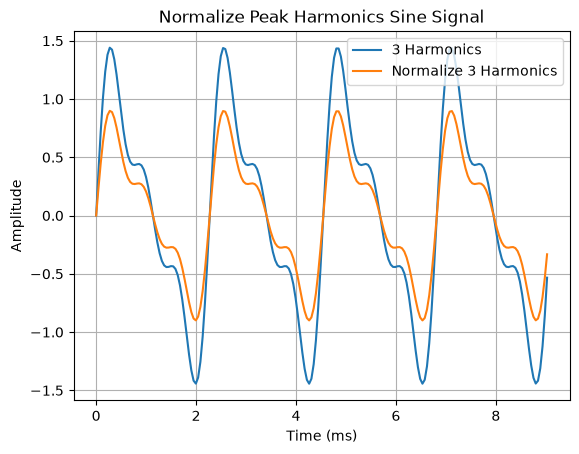

Peak of signal before normalize : 1.4428062860898088
Peak of signal after normalize : 0.8999999999999999
Check normalization : True


In [9]:
# -- Plot Graph --
fig, ax = plt.subplots()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Normalize Peak Harmonics Sine Signal")
ax.grid()
ax.plot(t[:200]*1000, sine_with_3_harmonics[:200], label="3 Harmonics")
ax.plot(t[:200]*1000, normalize_sine_with_3_harmonics[:200], label="Normalize 3 Harmonics")
ax.legend(loc="upper right")

plt.show()

# -- แสดงการเปรียบเทียบระหว่างก่อนและหลัง Normalize
print(f"Peak of signal before normalize : {np.max(np.abs(sine_with_3_harmonics))}")
print(f"Peak of signal after normalize : {np.max(np.abs(normalize_sine_with_3_harmonics))}")

# -- Check Normalize --
print(f"Check normalization : {np.isclose(np.max(np.abs(normalize_sine_with_3_harmonics)), 0.9)}")

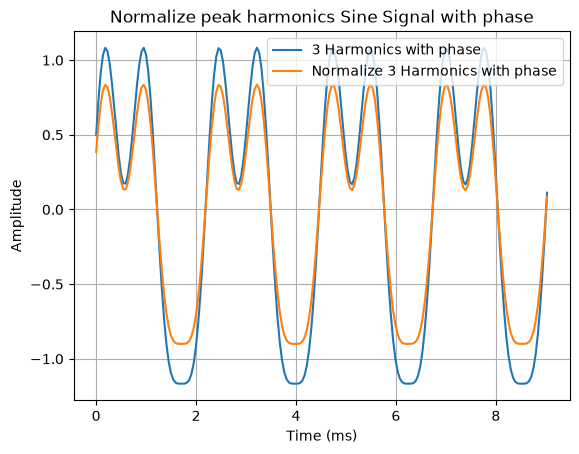

Peak of signal before normalize : 1.1666666666664733
Peak of signal after normalize : 0.9
Check normalization : True


In [10]:
# -- Plot Graph --
fig, ax = plt.subplots()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Normalize peak harmonics Sine Signal with phase")
ax.grid()
ax.plot(t[:200]*1000, sine_with_3_harmonics_phase[:200], label="3 Harmonics with phase")
ax.plot(t[:200]*1000, normalize_sine_with_3_harmonics_with_phase[:200], label="Normalize 3 Harmonics with phase")
ax.legend(loc="upper right")

plt.show()

# -- แสดงการเปรียบเทียบระหว่างก่อนและหลัง Normalize
print(f"Peak of signal before normalize : {np.max(np.abs(sine_with_3_harmonics_phase))}")
print(f"Peak of signal after normalize : {np.max(np.abs(normalize_sine_with_3_harmonics_with_phase))}")

# -- Check Normalize --
print(f"Check normalization : {np.isclose(np.max(np.abs(normalize_sine_with_3_harmonics_with_phase)), 0.9)}")

In [11]:
# ทำการซ้อนสัญญาณ 3 ตัวเข้าด้วยสัญญาณ Sine ที่มีความถี่ 440 Hz, Harmonics ที่มีเฟสและไม่มีเฟส
combined_signal = np.stack([sine_440, sine_with_3_harmonics, sine_with_3_harmonics_phase])
gain_1 = np.array([[1.0], [0.5], [0.25]])
gain_2 = np.array([1.0, 0.5, 0.25])

combined_signal_gain_1 = combined_signal * gain_1
print(f'Shape of combined signal with gain : {combined_signal_gain_1.shape}')

# ใช้งาน Try/Except
try:
    combined_signal_gain_2 = combined_signal * gain_2
except ValueError as e:
    print(f"Error : {e}")

# เลขตัวแรกเป็นแถวและเลขตัวหลังเป็นจำนวนหลักของแต่ละข้อมูล เช่น แถวแรกแทนด้วยข้อมูลของสัญญาณ Sine 440 Hz ของทั้ง 22050 Samples
print("Shape of combined signal")
print("------------------------")
print(f'Rows of combined signal : {combined_signal.shape[0]}')
print(f'Column of combined signal : {combined_signal.shape[1]}')

# axis = 1 ต้องการค่าที่มากที่สุดของแต่ละแถว 
# axis = 0 ต้องการค่าที่มากที่สุดของแต่ละ Column
print(f'Peaks of each rows : {(np.max(np.abs(combined_signal), axis=1))}')
print(f'Peaks of each rows with gain_1 : {(np.max(np.abs(combined_signal_gain_1), axis=1))}')

Shape of combined signal with gain : (3, 22050)
Error : operands could not be broadcast together with shapes (3,22050) (3,) 
Shape of combined signal
------------------------
Rows of combined signal : 3
Column of combined signal : 22050
Peaks of each rows : [0.99999975 1.44280629 1.16666667]
Peaks of each rows with gain_1 : [0.99999975 0.72140314 0.29166667]


**N4 (หู) ฟังเทียบให้ยุติธรรม: `Audio` normalize ให้อัตโนมัติ**
  - **สร้างอะไร:** sine 440 Hz ยาว 2 วินาที สองตัว: แอมพลิจูด 1.0 และ 0.25
  - **ฟังรอบที่ 1:** ทั้งสองตัวด้วย `Audio(x, rate=sr)` (ค่า default)
  - **ฟังรอบที่ 2:** ทั้งสองตัวด้วย `Audio(x, rate=sr, normalize=False)`
  - **ตอบ 3 ข้อ:** (1) รอบที่ 1 ความดังต่างกันไหม รอบที่ 2 ต่างกันไหม (2) 0.25 เทียบกับ 1.0 เบากว่ากี่ dB (ใบ้: $20\log_{10}$ ของอัตราส่วน) (3) ย้อนดู T3/T4 ของเมื่อวาน: การฟังเทียบตอนนั้นใช้ default หรือเปล่า และถ้าจะเทียบ timbre ให้ยุติธรรมควรทำอย่างไร (ใช้ `normalize_peak` จาก N3 + `normalize=False`)
  - **เสร็จเมื่อ:** มีเซลล์ Audio ครบ 4 ตัวและตอบครบ 3 ข้อ

  ---

  **ตอบ** : 
  1. รอบที่ 1 ความดังไม่มีความแตกต่างกัน แต่ว่ารอบที่ 2 มีความแตกต่างกันโดยที่สัญญาณ Sine ที่มีแอมพลิจูดเท่ากับ 1 มีเสียงที่ดังกว่าสัญญาณ Sine ที่มีแอมพลิจูดเท่ากับ 0.25

  2. จากสมการจะเปรียบเทียบระหว่างสัญญาณ Sine ที่มีแอมพลิจูดเท่ากับ 0.25 มีเสียงที่เบากว่าสัญญาณ Sine ที่มีแอมพลิจูดเท่ากับ 1 กี่ dB สามารถคำนวณได้จาก \
  $20log_{10}{(\frac{A_{1}}{A_{2}})} = 20log_{10}{(\frac{0.25}{1})} = -12.04 dB$

  3. เมื่อวานแล็ป T3-T4 มีการใช้งาน Default Normalize ถ้าต้องการเทียบ Timbre ให้ยุติธรรมจะต้องมีการกำหนด Normalize Peak เอาไว้ เพื่อป้องกันไม่ให้ระดับความดังของเสียงมีผลต่อการวิเคราะห์ Timbre
  วิธีป้องกันจะต้องนำสัญญาณผ่าน function normalize_peak เพื่อปรับให้แอมพลิจูดของสัญญาณเท่ากันหมด โดยจะต้องตั้ง Target เอาไว้ที่ 0.9 ตามที่ได้มีการทดลองในวันนี้เพื่อไม่ให้ระดับเสียงดังจนเกินไป จากนั้นจะต้องมีการตั้งค่า parameter ของ Audio โดยกำหนดให้ `normalize=False` เพื่อไม่ให้ function Audio มาปรับแอมพลิจูดอีก

In [12]:
from IPython.display import Audio
t_2s = np.arange(0, 2, 1/sr)
sine_440_2s_1A = create_sin(1, frequency, t_2s)
sine_440_2s_0_25A = create_sin(0.25, frequency, t_2s)

# แสดงผลลัพธ์เสียงคลื่นความถี่ 440 Hz แอมพลิจูดเท่ากับ 1
Audio(sine_440_2s_1A, rate=sr)

In [13]:
# แสดงผลลัพธ์เสียงคลื่นความถี่ 440 Hz แอมพลิจูดเท่ากับ 0.25
Audio(sine_440_2s_0_25A, rate=sr)

In [14]:
# แสดงผลลัพธ์เสียงคลื่นความถี่ 440 Hz แอมพลิจูดเท่ากับ 1 โดยไม่มีการ Normalize
Audio(sine_440_2s_1A, rate=sr, normalize=False)

In [15]:
# แสดงผลลัพธ์เสียงคลื่นความถี่ 440 Hz แอมพลิจูดเท่ากับ 0.25 โดยไม่มีการ Normalize
Audio(sine_440_2s_0_25A, rate=sr, normalize=False)